# Praktikum 3
SVM pada Data Overlapping

Pada dua praktikum sebelumnya, decision boundary bisa memisahkan data dengan jelas karena **tidak ada titik yang tumpang tindih**. Pada data nyata, hampir selalu ada titik satu kelas yang "nyasar" ke wilayah kelas lain.

Solusinya adalah **soft margin**: sebagian pelanggaran margin diperbolehkan, dengan penalti yang diatur parameter **`C`**.

* `C` besar → penalti besar, model berusaha keras benar semua titik, margin sempit, berisiko **overfitting**.
* `C` kecil → penalti kecil, margin lebar dan lebih toleran terhadap kesalahan, tetapi bisa **underfitting**.

Data yang dipakai adalah `make_blobs` dengan `cluster_std` lebih besar sehingga kedua kelas saling beririsan.

### Langkah 1 - Import Library dan Buat Fungsi Plotting

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

sns.set(style='whitegrid')

In [2]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Plot batas keputusan dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # Plot support vector
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

### Langkah 2 - Buat Data Dummy
`cluster_std=1.2` membuat sebaran tiap kelas melebar sehingga sebagian titik masuk ke wilayah kelas lain.

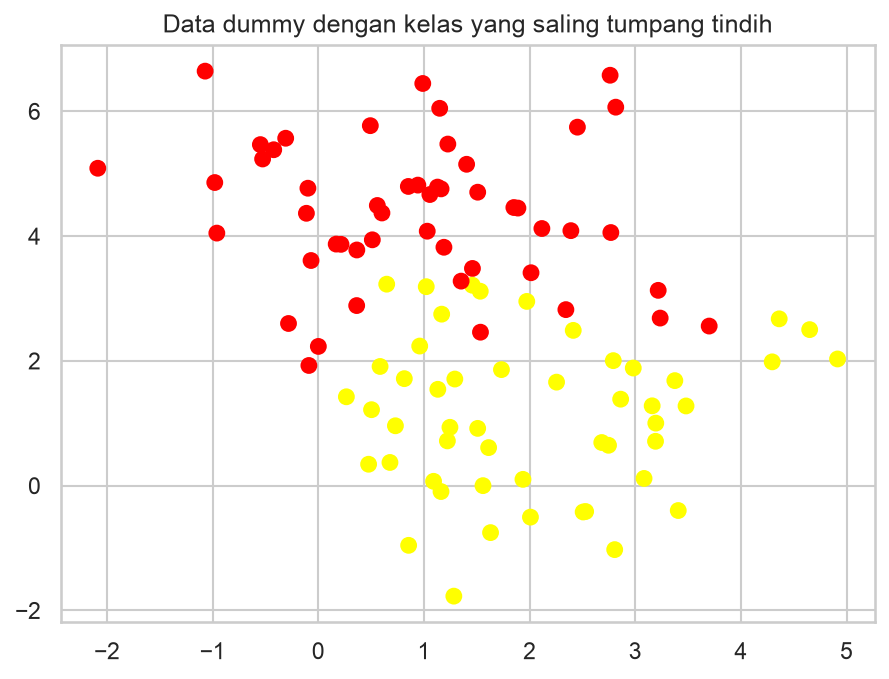

In [3]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.title('Data dummy dengan kelas yang saling tumpang tindih')
plt.show()

### Langkah 3 - Analisis Dampak Tunning
Teknik penghalusan margin (*soft margin*) memasukkan sebagian titik ke dalam margin agar fitting lebih baik. Ketebalan toleransi diatur oleh `C`. Perhatikan pengaruh `C = 10` dibanding `C = 0.1` pada data yang sama.

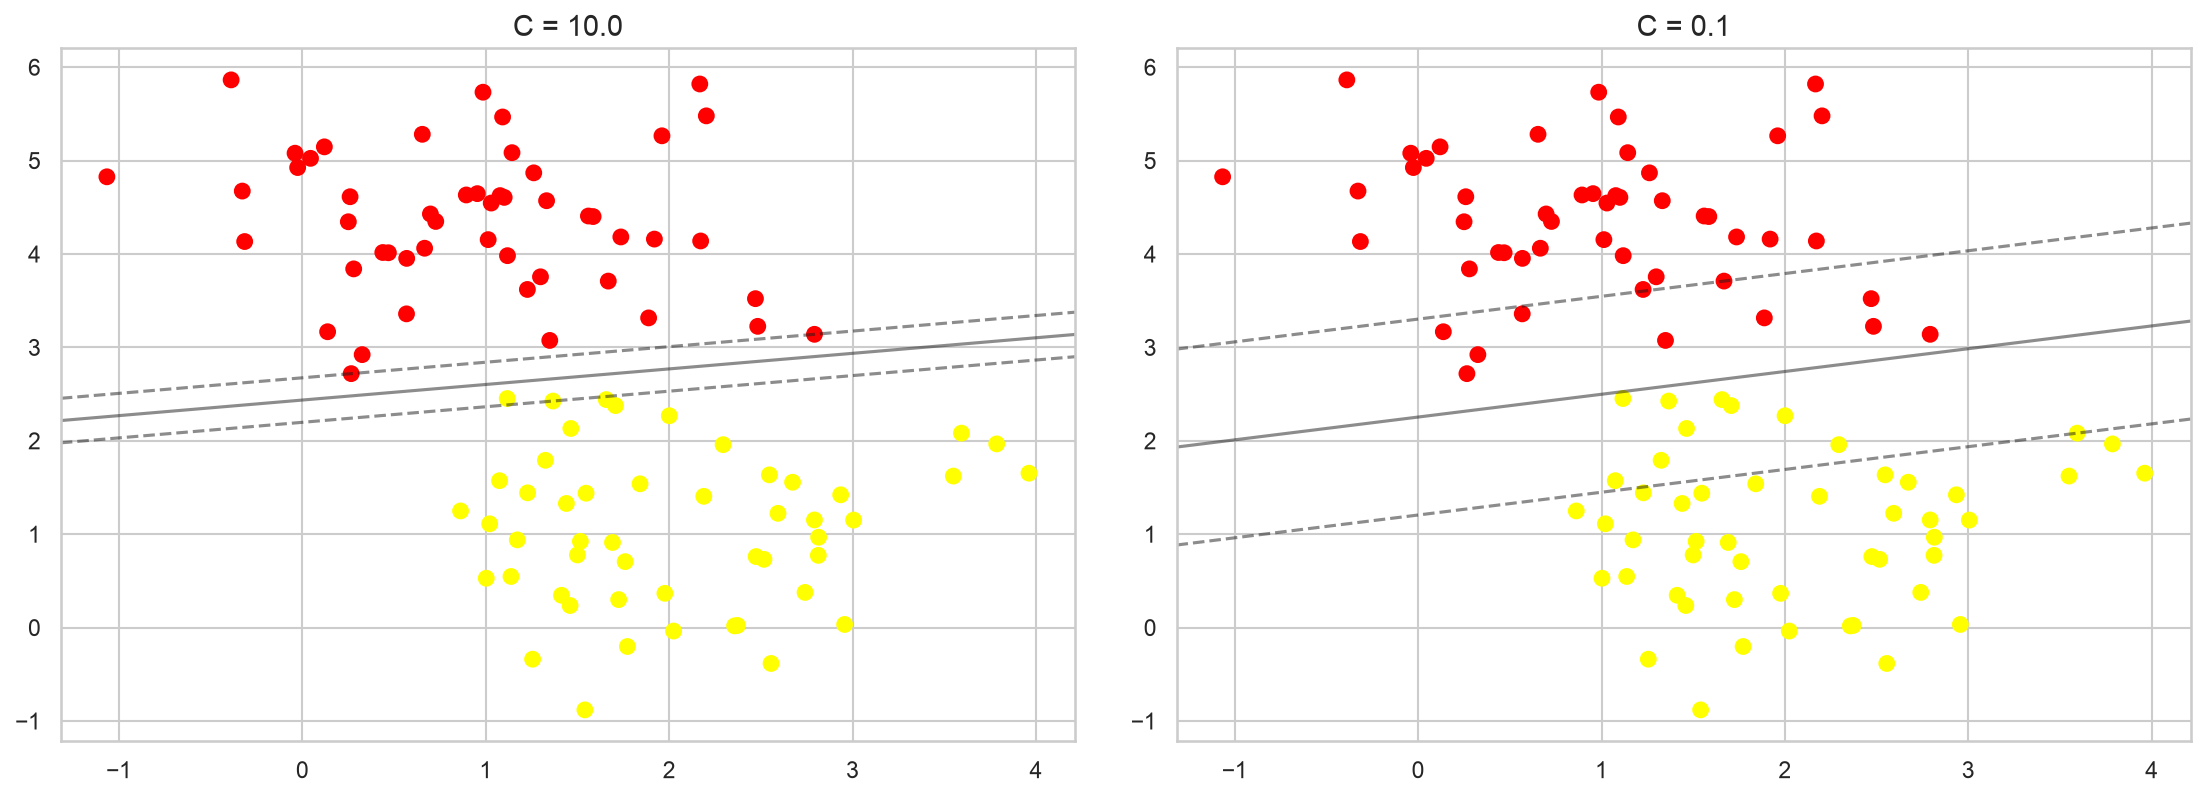

In [4]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none')
    axi.set_title('C = {0:.1f}'.format(C), size=14)

plt.show()

Nilai optimal `C` bergantung pada dataset dan sebaiknya dicari lewat **cross-validation**, bukan ditebak. Berikut rekap pengaruh `C` terhadap lebar margin, jumlah support vector, dan akurasi.

In [5]:
baris = []
for C in [0.01, 0.1, 1, 10, 100]:
    m = SVC(kernel='linear', C=C).fit(X, y)
    lebar_margin = 2 / np.linalg.norm(m.coef_)   # jarak antar batas margin
    baris.append({
        'C': C,
        'Lebar margin': lebar_margin,
        'Jumlah support vector': int(m.n_support_.sum()),
        'Akurasi latih': m.score(X, y),
    })

rekap = pd.DataFrame(baris)
rekap.round(4)

,C,Lebar margin,Jumlah support vector,Akurasi latih
0,0.01,3.5802,52,0.99
1,0.10,2.0380,20,1.00
2,1.00,0.8740,9,1.00
3,10.00,0.4702,4,1.00
4,100.00,0.4030,3,1.00


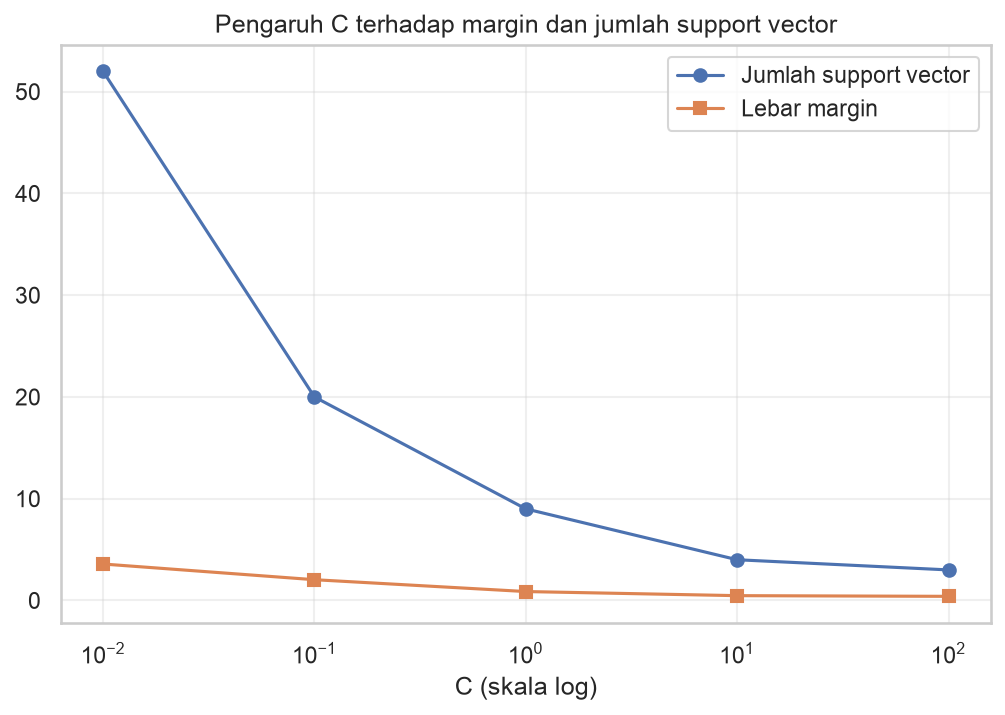

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(rekap['C'], rekap['Jumlah support vector'], marker='o', label='Jumlah support vector')
plt.plot(rekap['C'], rekap['Lebar margin'], marker='s', label='Lebar margin')
plt.xscale('log')
plt.xlabel('C (skala log)')
plt.title('Pengaruh C terhadap margin dan jumlah support vector')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Kesimpulan

* Data yang tumpang tindih tidak dapat diselesaikan dengan *hard margin*; dibutuhkan **soft margin** yang mengizinkan pelanggaran dengan penalti.
* `C` kecil (`0.1`) menghasilkan margin **lebar** dengan lebih banyak titik masuk ke dalam margin (lebih banyak support vector), sehingga model lebih toleran terhadap noise.
* `C` besar (`10` dan seterusnya) memaksa margin **sempit**; model mengejar semua titik benar dan cenderung **overfitting** — pada data uji baru performanya bisa justru turun.
* Akurasi latih saja tidak cukup untuk memilih `C`, karena nilai terbesar biasanya datang dari model paling kaku. Gunakan **cross-validation** untuk memilih `C` (lihat Praktikum 4 yang memakai `GridSearchCV`).